# Evaluate

Load a trained checkpoint and compare it with the simulator. Nothing here trains; checkpoints come
from `notebooks/chunk/train.ipynb`.

Sections 1-6 evaluate one checkpoint, picked by profile and objective (regression or diffusion). A
diffusion model shows one sample per prediction in plots. In section 4 it is scored both as one
sample and as the mean of several. Section 7 compares a regression and a diffusion checkpoint on the
same pairs.

Sections:

1. **Training summary**: what the checkpoint was trained on, and its loss curves.
2. **Predictions**: the model next to the simulator on random validation pairs.
3. **Animation**: one run eroded by the model and by the simulator, as a GIF.
4. **Accuracy**: height error, rivers, fine detail, where the model fails, and chained calls.
5. **Speed**: time per model call against the simulator.
6. **Variable elapsed time**: for a model trained on many elapsed times (`variable_dt`): random start
   and elapsed times, error against elapsed time, and an animation with one model call per frame.
7. **Regression against diffusion**: two checkpoints trained on the same data, side by side, on every
   metric of section 4 plus the spread across diffusion samples. Runs on its own after the imports.

In [ ]:
from IPython.display import Image as ShowImage

from erosion_sim.data import Split
from erosion_sim.evaluate import (comparison_gif, error_by_condition, error_by_elapsed, error_metrics, hydrology_metrics, predict_pairs,
                                  rollout_error, sample_spread, show_comparison, show_predictions, spectrum_comparison,
                                  speed_comparison, step_sweep)
from erosion_sim.paths import CHECKPOINTS_DIR, checkpoint_path
from erosion_sim.train import load_checkpoint, plot_history

print("saved checkpoints:")
for path in sorted(CHECKPOINTS_DIR.glob("*.pt")):
    if not path.stem.endswith("-last"):
        print(" ", path.name)

## 1. Training summary

In [ ]:
PROFILE = "variable_dt"
OBJECTIVE = "diffusion"  # "regression" or "diffusion"
CHECKPOINT = checkpoint_path(PROFILE, OBJECTIVE)

model, scaling, cfg, ckpt = load_checkpoint(CHECKPOINT)
history = ckpt["history"]
print(f"{cfg.objective} {cfg.profile}: saved at step {ckpt['step']} of {cfg.steps}, "
      f"best validation skill {max(history['val_skill']):.3f}")
print(f"runs: {dict(cfg.runs) or 'all'}")
print(f"elapsed times (snapshot steps of 1,000 yr): {cfg.lags if cfg.lags is not None else 'all'}")
plot_history(history)

## 2. Predictions

Each row is one random validation pair from runs that match the checkpoint's run filter. A pair can
start at any snapshot of its run; only the gap between start and end is fixed by the profile.
Columns: start, simulator end, model end, simulator change, model change, and the error.

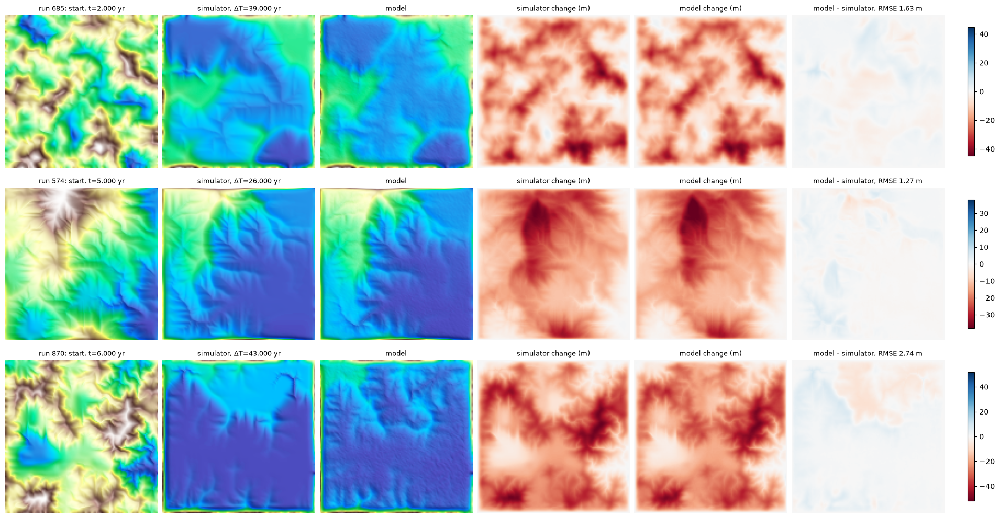

In [3]:
show_predictions(CHECKPOINT, count=3, seed=0)

## 3. Animation: simulator against model

Erodes one run with the model, starting from the simulator's snapshot at t = 0, and animates it next
to the simulator. Top row 2D, bottom row 3D with rivers in blue; both share one color scale and camera.
The GIF is saved to `artifacts/animations/`.

- `MODE = "rollout"` feeds each prediction back in as the next start, `LAG` snapshots at a time. A
  model trained on one elapsed time (`fixed_dt`) can only be used this way, and errors add up.
- `MODE = "direct"` predicts every frame straight from t = 0. Only meaningful for a model trained on
  many elapsed times (`variable_dt`).
- `LAG = None` uses the model's training elapsed time if it has one, else 1 snapshot (1,000 yr).

`INDEX` picks from the split's runs that match the checkpoint's run filter (for example, no uplift).

In [ ]:
SPLIT = "val"
INDEX = 0
MODE = "direct"
LAG = None
FPS = 2

matching = Split.open(cfg.data_profile, SPLIT).select(**dict(cfg.runs))
RUN = int(matching[INDEX])
print(f"{len(matching)} matching {SPLIT} runs; showing run {RUN}")

gif = comparison_gif(CHECKPOINT, run=RUN, split=SPLIT, lag=LAG, mode=MODE, fps=FPS)
print(f"saved {gif}")
ShowImage(filename=gif)

## 4. Accuracy

The model is compared with the simulator, in meters. **No change** (the end terrain equals the start)
is shown as a reference row: skill is defined against it, and it shows what the river numbers mean.

The cell below runs the model once on `COUNT` random validation pairs (from runs
matching the checkpoint's run filter, at its training elapsed times). The cells after it reuse them.

In [5]:
COUNT = 256  # about 1 minute with the river metrics, for regression
SAMPLES = 4  # diffusion only: samples per pair. Diffusion costs about 63 network calls per sample; use fewer pairs
pairs = predict_pairs(CHECKPOINT, split="val", count=COUNT, seed=0, samples=SAMPLES)

model: 100%|██████████| 256/256 [01:28<00:00,  2.89pair/s]


### 4.1 Height error

- **RMSE**: root mean squared error of the end heightmap, in m.
- **Skill**: `1 - MSE / MSE(no change)`, where MSE is mean squared error. The fraction of the
  simulator's change the method gets right, in squared terms. 0 is no better than doing nothing, 1 is
  perfect, below 0 is worse than doing nothing. Over all pairs together, and the median per pair.
- **Erosion ratio**: how much the method changes the terrain over how much the simulator does.
  1 is right; below 1 is too little.

In [6]:
errors = error_metrics(pairs)

256 pairs; simulator's mean absolute change 5.726 m

           method  RMSE (m)   skill  median skill  erosion ratio
        no change     8.926   0.000         0.000          0.000
 model (1 sample)     0.890   0.990         0.994          0.983
model (mean of 4)     0.778   0.992         0.995          0.984


### 4.2 Rivers

Water is routed over each end heightmap (D8: each cell drains to its steepest downhill neighbor, no pit
filling). Channels are cells whose drainage area is at least the simulator's 95% quantile.

- **Channel IoU**: intersection over union of the method's channel cells and the simulator's. 1 is a
  perfect match. A channel one cell off counts as a miss.
- **IoU, 1 cell**: the same after widening both channel masks by one cell, so small shifts still match.
- **log10 area RMSE**: error in drainage area, on a log scale, over every cell.
- **Pits**: interior cells with no lower neighbor. Water stops at a pit, so pits break rivers. The
  simulator's terrain has a few too; compare with its count.

No change is a real baseline here: most of the start terrain's rivers survive.
The plot shows the channels of one pair.

channel threshold: drainage area >= 97 cells (simulator's 95% quantile)
simulator: 5.6 pits per terrain

           method  channel IoU  IoU, 1 cell  log10 area RMSE    pits
        no change        0.467        0.626            0.512    11.5
 model (1 sample)        0.409        0.578            0.529   126.2
model (mean of 4)        0.467        0.642            0.486    85.4


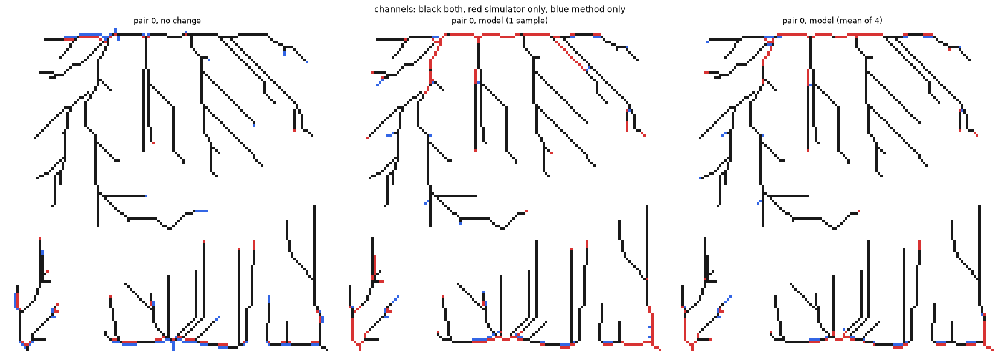

In [7]:
hydro = hydrology_metrics(pairs, example=0)

### 4.3 Fine detail

Power spectrum of the change (end minus start): how much of the change happens at each scale,
averaged over pairs. Right is fine detail. On the right panel, 1 means the model matches the
simulator at that scale; below 1 means detail is smoothed away.

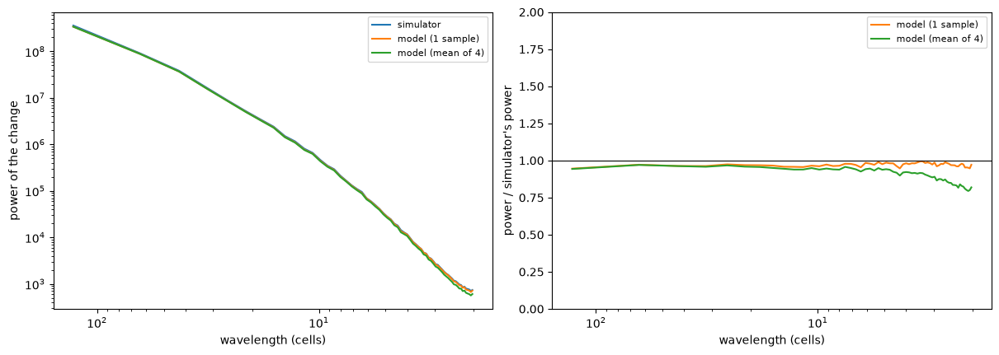

In [8]:
spectrum = spectrum_comparison(pairs)

### 4.4 Where the model fails

Skill per pair against each parameter, the start time, and the elapsed time. Dots are pairs; lines
are medians in bins with equal numbers of pairs. Parameters with one value in the sample (for example
uplift for `fixed_dt`) are skipped.

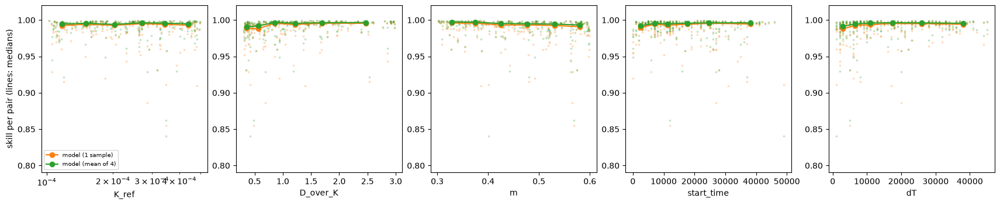

In [9]:
by_condition = error_by_condition(pairs)

### 4.5 Chained calls

Error against elapsed time from t = 0, over `RUNS` validation runs.

- **rollout**: each model call starts from the model's previous output.
- **one call**: one model call from the simulator's terrain one step earlier. The gap between this and
  rollout is the error added by chaining.
- **direct**: one model call from t = 0 straight to each time. Shown only for a model trained on every
  one of those elapsed times (`variable_dt`).
- **no change**: the terrain at t = 0.

Skill here is against no change from t = 0.

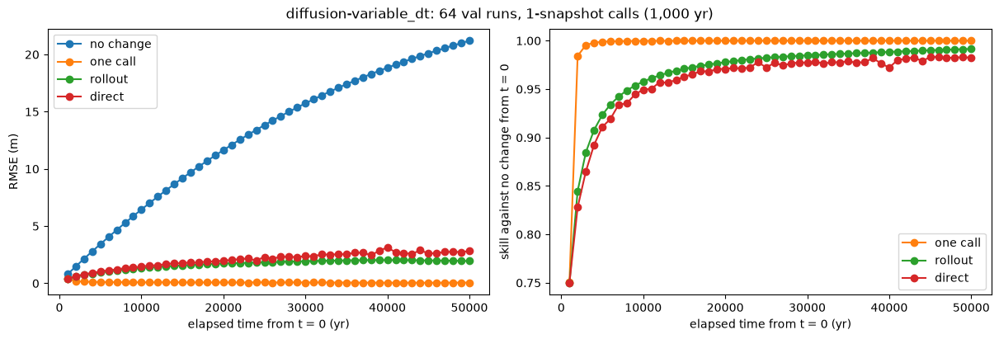

In [10]:
RUNS = 64
chained = rollout_error(CHECKPOINT, split="val", runs=RUNS)

## 5. Speed

Time to erode one 128×128 terrain by each elapsed time.

- **Simulator**: timed now, on one CPU core, on the same run's parameters, in the `datagen`
  environment. Its cost grows with the elapsed time: one 100-yr step at a time.
- **Model**: one call per elapsed time it was trained on. To cover a longer time, calls are chained
  (rollout), so the cost is the number of calls times one call. If no combination of its trained
  elapsed times adds up exactly, the model cannot produce that time: `fixed_dt` only does multiples of
  10,000 yr.
- Model times are shown on the CPU, on the GPU, and per terrain when 64 terrains go through the GPU
  together.

In [12]:
speed = speed_comparison(CHECKPOINT, split="val", run=RUN)

simulator: 3.88 ms per 100-yr step, one CPU core
diffusion model: one call is one sample, 32 sampler steps (63 network calls)
model: 2144.1 ms per call on CPU, 142.6 ms on GPU, 107.18 ms per terrain in batches of 64
model trained on elapsed times (yr): [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000, 11000, 12000, 13000, 14000, 15000, 16000, 17000, 18000, 19000, 20000, 21000, 22000, 23000, 24000, 25000, 26000, 27000, 28000, 29000, 30000, 31000, 32000, 33000, 34000, 35000, 36000, 37000, 38000, 39000, 40000, 41000, 42000, 43000, 44000, 45000, 46000, 47000, 48000, 49000, 50000]

  elapsed time    simulator  model calls   model, CPU   model, GPU  GPU, batched
      1,000 yr      38.8 ms            1    2144.1 ms     142.6 ms      107.2 ms
     10,000 yr     388.5 ms            1    2144.1 ms     142.6 ms      107.2 ms
     25,000 yr     971.2 ms            1    2144.1 ms     142.6 ms      107.2 ms
     50,000 yr    1942.3 ms            1    2144.1 ms     142.6 ms      107.2 ms

## 6. Variable elapsed time

For a model trained on many elapsed times (`variable_dt`). Every pair here is from the validation split:
runs (terrains and parameters) the model never trained on, from the same distribution. The test split
stays untouched for final numbers.

### 6.1 Random start and elapsed times

Each row is a random validation pair: a random run, start snapshot, and elapsed time. Columns as in
section 2. Change `SEED` for another draw.

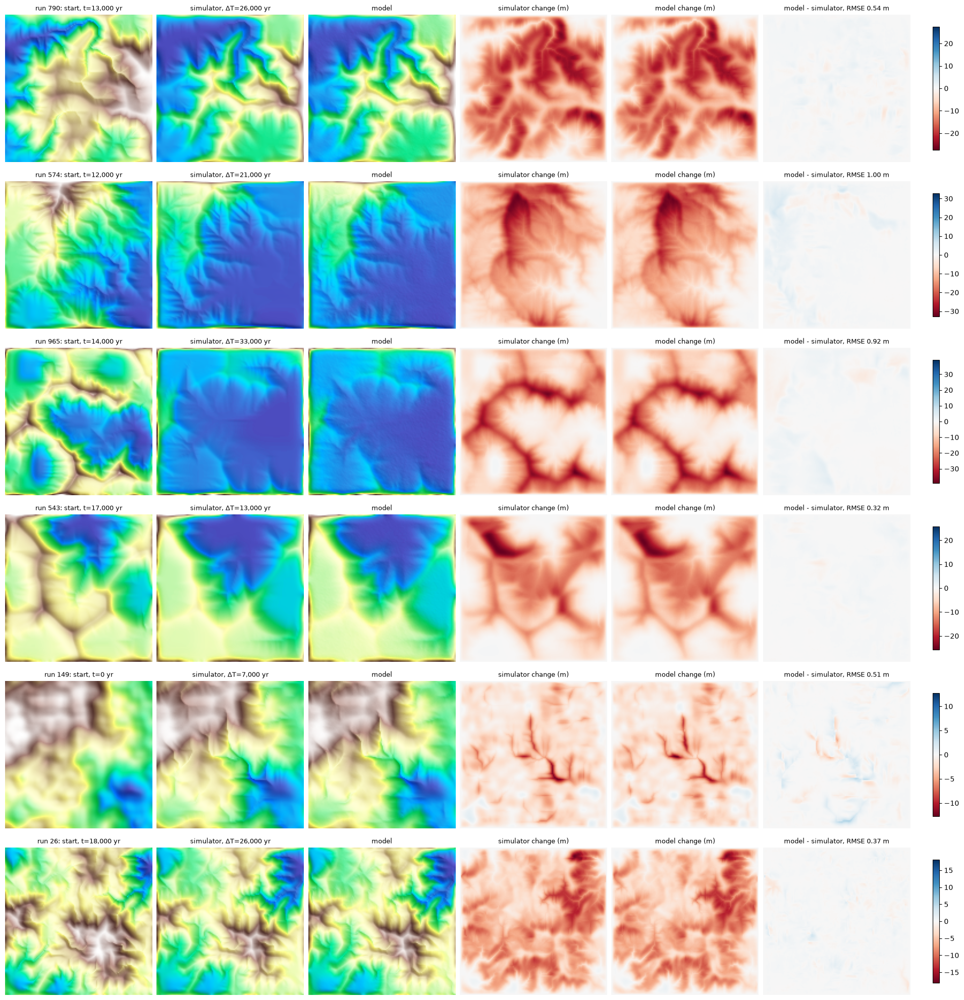

In [13]:
SEED = 1
show_predictions(CHECKPOINT, count=6, seed=SEED)

### 6.2 Error against elapsed time

Uses the pairs from section 4, grouped by elapsed time into bins with equal numbers of pairs.

- **RMSE**: in m. Grows with elapsed time, because the change itself grows.
- **Skill**: against no change, for the pairs in each bin. Flat means the model is equally good,
  relative to the size of the change, at every elapsed time.
- **Channel IoU**: as in section 4.2. No change is the line to beat: its rivers are the start's.
- **Grid**: median skill per pair, by start time and elapsed time. The empty corner is end times past
  the last snapshot (50,000 yr).

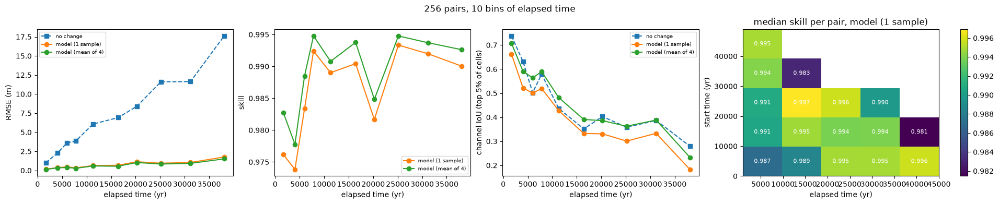

In [14]:
by_elapsed = error_by_elapsed(pairs)

### 6.3 Animation with one model call per frame

Like section 3, but every frame is its own model call straight from the simulator's terrain at t = 0
(`MODE = "direct"`): frame k asks the model to erode the t = 0 terrain for k × `LAG` snapshots. No
output is fed back in, so errors cannot add up from frame to frame. `LAG = 1` gives 51 frames, 1,000 yr
apart; about 20 seconds.

In [ ]:
INDEX = 0
LAG = 1
FPS = 6

matching = Split.open(cfg.data_profile, "val").select(**dict(cfg.runs))
RUN = int(matching[INDEX])
print(f"{len(matching)} matching val runs; showing run {RUN}")

gif = comparison_gif(CHECKPOINT, run=RUN, split="val", lag=LAG, mode="direct", fps=FPS)
print(f"saved {gif}")
ShowImage(filename=gif)

## 7. Regression against diffusion

Step 7 of `docs/plans/diffusion-plan.md`. Both checkpoints must be trained on the same data (same data
profile, run filter, and elapsed times), so they are scored on the same validation pairs. This section
only needs the imports cell.

Methods in the tables and plots:

- **no change**: the start terrain, as in section 4.
- **regression**: the U-Net's direct prediction, the mean of the possible answers.
- **diffusion (1 sample)**: one diffusion sample. This is what the model would actually give you.
- **diffusion (mean of N)**: the mean of N samples. It should be close to regression in pixel error,
  since both estimate the mean.

What to look for. On pixel error (RMSE), one sample is expected to be *worse* than regression: a
sample commits to one answer where regression averages over several. The case for diffusion is
sharper detail and better rivers: the power spectrum ratio closer to 1 at short wavelengths, higher
channel IoU, and pit counts closer to the simulator's.

In [17]:
COMPARE_PROFILE = "variable_dt"
CHECKPOINTS = {objective: checkpoint_path(COMPARE_PROFILE, objective) for objective in ("regression", "diffusion")}
COMPARE_COUNT = 512  # pairs. Diffusion cost: COUNT x SAMPLES x 63 network calls; roughly minutes, not seconds
COMPARE_SAMPLES = 8

### 7.1 Side by side

Each row is one random validation pair. Columns: start, simulator change, regression change, two
diffusion samples, and the spread (per-pixel standard deviation) across those two samples. If the
samples differ from each other, look at where: that is where the model is unsure.

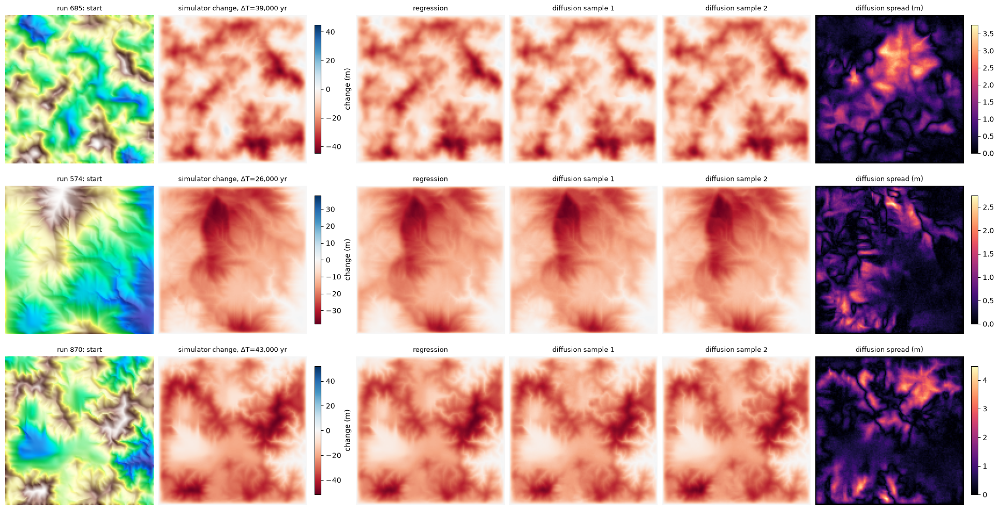

In [18]:
show_comparison(CHECKPOINTS, count=3, seed=0)

### 7.2 Scores on the same pairs

The cell below runs every model on `COMPARE_COUNT` pairs. The cells after it reuse them. Metrics are
the ones in section 4; see there for definitions.

In [19]:
compare = predict_pairs(CHECKPOINTS, split="val", count=COMPARE_COUNT, seed=0, samples=COMPARE_SAMPLES)

diffusion: 100%|██████████| 512/512 [05:50<00:00,  1.46pair/s]


In [20]:
compare_errors = error_metrics(compare)

512 pairs; simulator's mean absolute change 6.435 m

               method  RMSE (m)   skill  median skill  erosion ratio
            no change     9.740   0.000         0.000          0.000
           regression     0.889   0.992         0.995          1.000
 diffusion (1 sample)     0.996   0.990         0.993          0.987
diffusion (mean of 8)     0.837   0.993         0.995          0.986


channel threshold: drainage area >= 98 cells (simulator's 95% quantile)
simulator: 5.5 pits per terrain

               method  channel IoU  IoU, 1 cell  log10 area RMSE    pits
            no change        0.428        0.581            0.547    13.5
           regression        0.402        0.575            0.525    93.4
 diffusion (1 sample)        0.364        0.530            0.568   151.4
diffusion (mean of 8)        0.440        0.620            0.511    86.2


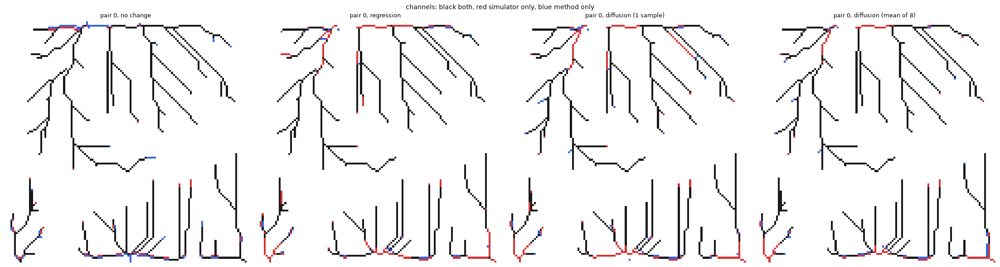

In [21]:
compare_hydro = hydrology_metrics(compare, example=0)

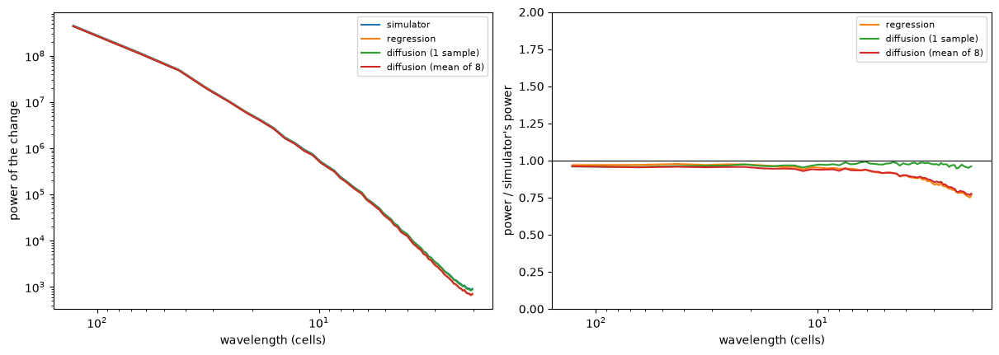

In [22]:
compare_spectrum = spectrum_comparison(compare)

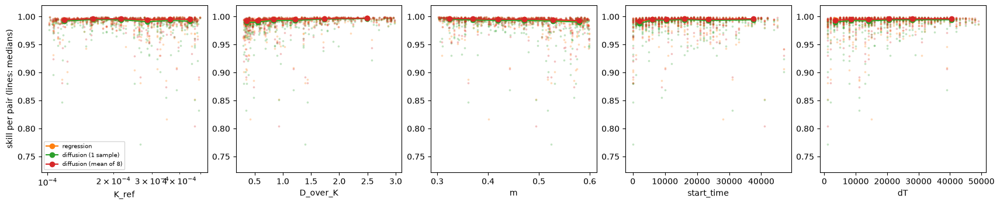

In [23]:
compare_by_condition = error_by_condition(compare)

### 7.3 Spread across samples

The spread is the per-pixel standard deviation across the diffusion model's samples. If the diffusion
model knows where it is unsure, errors should be larger where the spread is larger, for every method:
the left plot then rises from left to right. A positive correlation with regression's error means the
diffusion model is unsure in the same places where regression is wrong. The dashed line marks error
equal to spread.

diffusion: mean spread across samples 0.297 m

               method  corr(spread, |error|)
           regression                  0.637
 diffusion (1 sample)                  0.668
diffusion (mean of 8)                  0.647


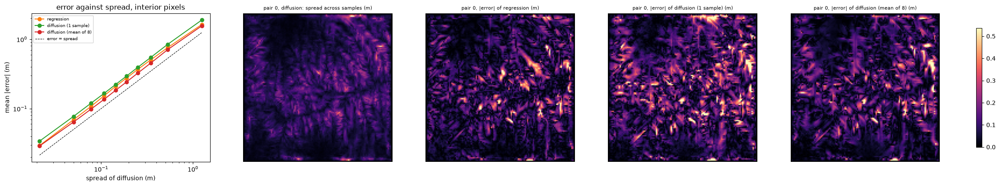

In [24]:
compare_spread = sample_spread(compare, example=0)

### 7.4 Chained calls

Section 4.5 for each model, on the same runs (same `seed`). The diffusion model draws one sample per
call.

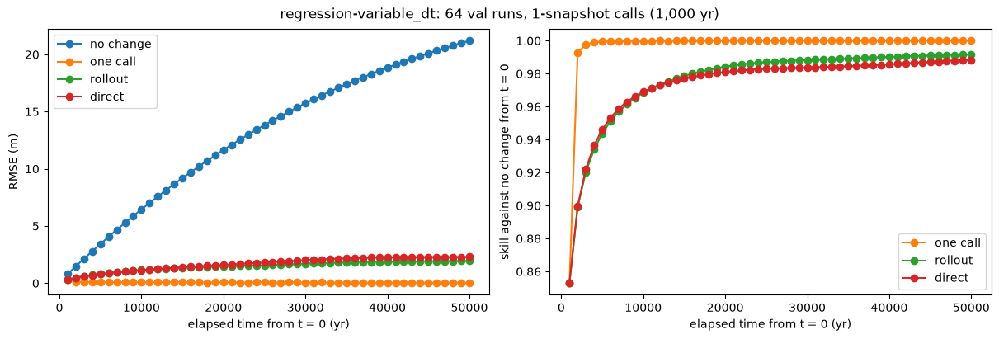

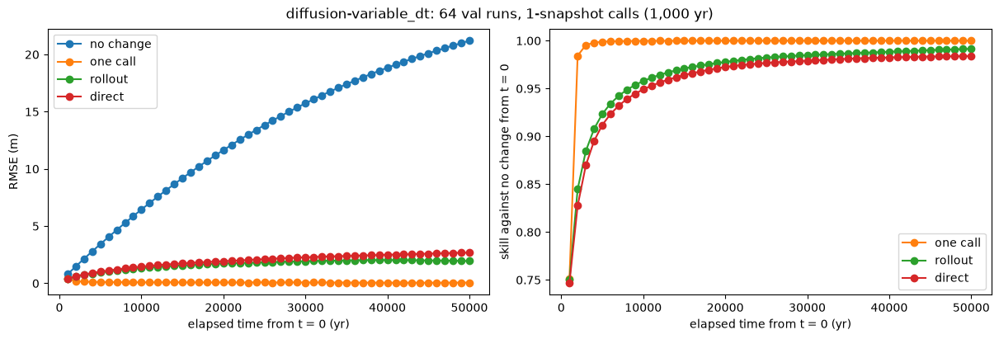

In [25]:
compare_chained = {name: rollout_error(path, split="val", runs=64, seed=0) for name, path in CHECKPOINTS.items()}

### 7.5 Speed

Section 5 for each model. One diffusion call is one full sample: 32 sampler steps, 63 network calls.

In [26]:
compare_speed = {}
for name, path in CHECKPOINTS.items():
    print(f"--- {name}")
    compare_speed[name] = speed_comparison(path, split="val", run=0)
    print()

--- regression
simulator: 4.17 ms per 100-yr step, one CPU core
model: 35.1 ms per call on CPU, 2.7 ms on GPU, 1.74 ms per terrain in batches of 64
model trained on elapsed times (yr): [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000, 11000, 12000, 13000, 14000, 15000, 16000, 17000, 18000, 19000, 20000, 21000, 22000, 23000, 24000, 25000, 26000, 27000, 28000, 29000, 30000, 31000, 32000, 33000, 34000, 35000, 36000, 37000, 38000, 39000, 40000, 41000, 42000, 43000, 44000, 45000, 46000, 47000, 48000, 49000, 50000]

  elapsed time    simulator  model calls   model, CPU   model, GPU  GPU, batched
      1,000 yr      41.7 ms            1      35.1 ms       2.7 ms        1.7 ms
     10,000 yr     417.3 ms            1      35.1 ms       2.7 ms        1.7 ms
     25,000 yr    1043.3 ms            1      35.1 ms       2.7 ms        1.7 ms
     50,000 yr    2086.6 ms            1      35.1 ms       2.7 ms        1.7 ms

--- diffusion
simulator: 4.28 ms per 100-yr step, one CPU core
dif

### 7.6 Sampler steps

Step 6 of `docs/plans/diffusion-plan.md`. The diffusion model is run with 8, 16, 32, and 64 sampler steps on
the same pairs and the same noise; nothing is retrained. Fewer steps is proportionally faster (a sample
costs `2 x steps - 1` network calls) and less accurate. Look for where the metrics stop improving.

- **RMSE**, **channel IoU** and **pits** as in section 4. Dashed: regression. Dotted: the simulator's
  pits, and no change's IoU.
- **Fine detail**: the power of the change at wavelengths up to 4 cells, over the simulator's (the
  right end of the spectrum plot in 7.2). 1 is right; below 1 is blurred; above 1 is noise.
- **ms per sample**: wall time of the whole prediction, per sample.

About 6 minutes at 256 pairs and 4 samples.

256 pairs, 4 samples each; simulator: 5.6 pits

diffusion, 1 sample
 steps  ms/sample  RMSE (m)    IoU   pits  fine
     8       21.3     1.006  0.280  284.6  1.47
    16       42.6     0.902  0.388  148.3  1.01
    32       86.5     0.890  0.409  126.2  0.97
    64      175.2     0.888  0.412  120.7  0.97

diffusion, mean of 4
 steps  ms/sample  RMSE (m)    IoU   pits  fine
     8       21.3     0.818  0.371  184.7  1.02
    16       42.6     0.782  0.454   98.5  0.87
    32       86.5     0.778  0.467   85.4  0.86
    64      175.2     0.778  0.470   82.0  0.86

regression: RMSE 0.859, IoU 0.442, pits 80.0, fine 0.84


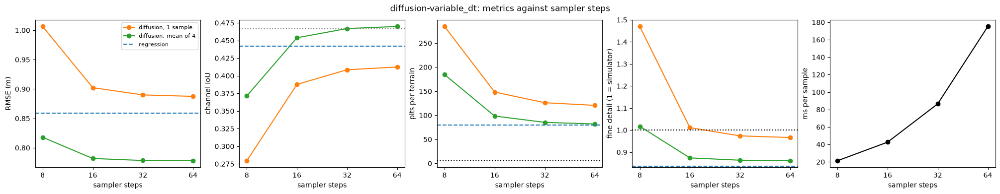

In [27]:
sweep = step_sweep(CHECKPOINTS["diffusion"], steps=(8, 16, 32, 64), regression=CHECKPOINTS["regression"],
                   split="val", count=256, samples=4, seed=0)